# Tutorial 1: a BEM from a T1, start to finish

This tutorial builds a three-layer BEM (inner skull, outer skull, skin) for EEG/MEG forward modelling from nothing but a T1-weighted MRI:

1. download a public T1 (11 MB),
2. segment the head with SimNIBS CHARM,
3. fit the BEM surfaces,
4. check and look at the result with the viewer of your choice,
5. hand it to MNE.

**Requirements**

```bash
pip install "mindmap-bem[tutorials]"     # + jupyter, matplotlib, MNE
```

and [SimNIBS ≥ 4.0](https://simnibs.github.io/simnibs/build/html/installation/simnibs_installer.html) for CHARM (`charm` on your `PATH`). FreeSurfer is **not** needed.

In [1]:
from pathlib import Path

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

import mindmap_bem as mb

DATA = mb.datasets.data_dir()            # ~/mindmap_bem_data, or $MINDMAP_BEM_DATA
DERIV = DATA/"derivatives"/"mindmap_bem"
SUBJECTS_DIR = DERIV/"subjects"           # MNE-style subjects directory
subject = "sub-01"
print(DATA)

/home/nino/mindmap_bem_data


## 1. Download a T1

We use subject 01 of [OpenNeuro ds000117](https://openneuro.org/datasets/ds000117) (Wakeman & Henson, 2015; CC0): a 1 mm isotropic MPRAGE from a 3T Siemens scanner, the most common kind of structural scan in EEG/MEG studies. The file is cached, so this cell only downloads once.

In [2]:
t1 = mb.datasets.fetch_example_t1("01")

img = nib.load(t1)
print(t1)
print("shape", img.shape, "| voxel size (mm)", img.header.get_zooms(), "| orientation", nib.aff2axcodes(img.affine))

/home/nino/mindmap_bem_data/ds000117/sub-01/anat/sub-01_T1w.nii.gz
shape (192, 256, 256) | voxel size (mm) (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | orientation ('R', 'A', 'S')


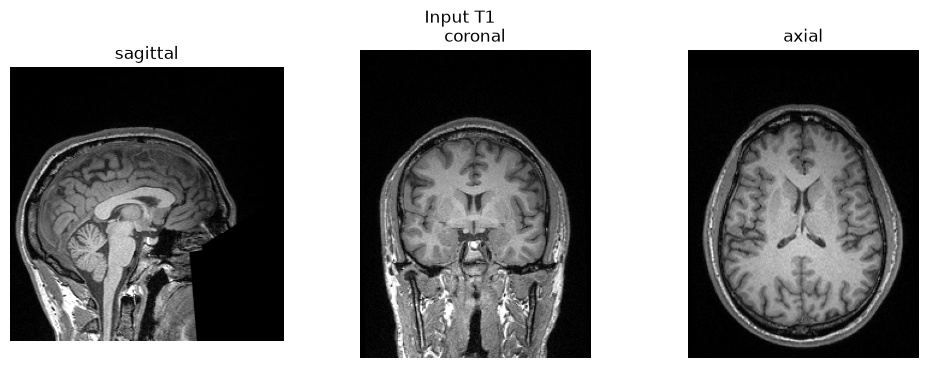

In [3]:
from matplotlib.colors import ListedColormap

def show_slices(img, overlay=None, title=None):
    """Mid sagittal, coronal and axial slices, optionally with a compartment overlay (1, 2, 3)."""
    img = nib.as_closest_canonical(img)
    data = img.get_fdata()
    over = None if overlay is None else nib.as_closest_canonical(overlay).get_fdata()
    cmap = ListedColormap([mb.viz.COLORS[k] for k in ("inner_skull", "outer_skull", "skin")])

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, k in zip(axes, range(3)):
        i = data.shape[k] // 2
        ax.imshow(np.take(data, i, axis=k).T, origin="lower", cmap="gray", vmax=np.percentile(data, 99.5))
        if over is not None:
            comp = np.take(over, i, axis=k).T
            ax.imshow(np.ma.masked_equal(comp, 0), origin="lower", cmap=cmap, vmin=1, vmax=3,
                      alpha=0.4, interpolation="nearest")
        ax.set_title(["sagittal", "coronal", "axial"][k])
        ax.set_axis_off()
    fig.suptitle(title)
    plt.show()

show_slices(img, title="Input T1")

Like most shared MRI data, this scan is **defaced**: the face has been removed for anonymity. The skull is untouched, so the skull layers are unaffected, but the skin surface will follow the cut over the face. Your own, non-defaced scans will not have this.

## 2. Segment the head with CHARM

CHARM labels every voxel of the head (scalp, bone, CSF, grey/white matter, ...). We only run its segmentation steps (`--initatlas --segment`), not the FEM meshing. This takes **about 15 minutes** once; afterwards the existing segmentation is reused.

In [4]:
m2m = mb.run_charm(subject, t1, DERIV)
labeling = mb.charm_labeling(m2m)
print(labeling)

/home/nino/mindmap_bem_data/derivatives/mindmap_bem/m2m_sub-01/segmentation/labeling.nii.gz


CHARM produces ~50 labels. The `charm` preset groups them into what each BEM layer must enclose; here is that grouping (red: inside the inner skull, orange: skull, green: scalp and other soft tissue):

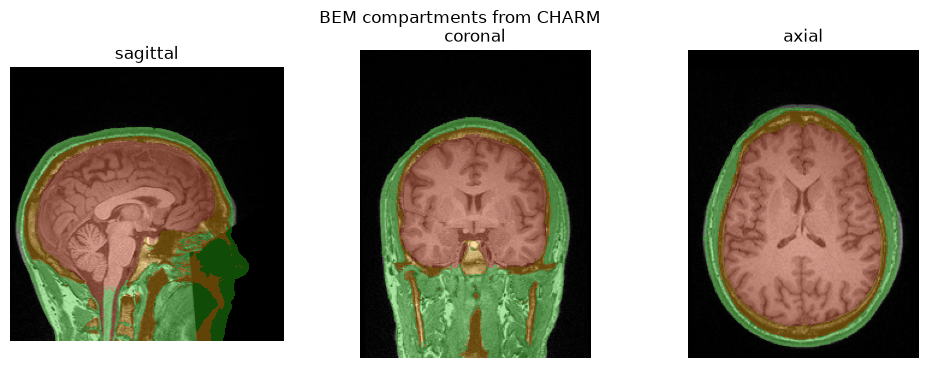

In [5]:
seg = nib.load(labeling)
labels = mb.read_bem_labels("charm")
seg_data = np.asanyarray(seg.dataobj)

compartments = np.zeros(seg.shape, dtype=np.uint8)
compartments[np.isin(seg_data, labels["skin"])] = 3
compartments[np.isin(seg_data, labels["outer_skull"])] = 2
compartments[np.isin(seg_data, labels["inner_skull"])] = 1

show_slices(img, overlay=nib.Nifti1Image(compartments, seg.affine), title="BEM compartments from CHARM")

## 3. Fit the BEM

Each layer is an icosahedral sphere (MNE's ico-5, 10242 vertices) shrink-wrapped onto the union of the tissues it encloses, fitted from the inside out so that each layer stays outside the previous one. The tissue → layer mapping comes from the bundled `charm` label preset.

We lay the result out as an **MNE subject**, so that MNE can use it without FreeSurfer:

- `setup_mne_subject` writes `SUBJECTS_DIR/<subject>/mri/T1.mgz` from our T1. MNE finds a subject's MRI through this file, and uses its coordinates as the subject's "MRI" frame.
- `build_bem(..., fs_t1=t1_mgz)` writes the surfaces in that frame, in `SUBJECTS_DIR/<subject>/bem/`.

(If the subject has a FreeSurfer reconstruction, its own `mri/T1.mgz` is used instead.)

In [6]:
t1_mgz = mb.setup_mne_subject(t1, SUBJECTS_DIR, subject)

bem_dir = SUBJECTS_DIR/subject/"bem"
layers = mb.build_bem(labeling, bem_dir, fs_t1=t1_mgz, overwrite=True)
sorted(p.name for p in bem_dir.iterdir())

['inner_skull.surf', 'outer_skin.surf', 'outer_skull.surf']

### Quality check

Before any forward model: every surface must be closed, and each layer must sit strictly inside the next one. Intersecting or touching layers are the classic failure of watershed BEMs.

In [7]:
mb.check_bem(layers)

inner_skull   10242 vertices, closed manifold: True
outer_skull   10242 vertices, closed manifold: True
skin          10242 vertices, closed manifold: True
inner_skull -> outer_skull gap min  2.67 mm, median  6.41 mm
outer_skull -> skin        gap min  3.49 mm, median  9.42 mm


True

## 4. Look at the result

Surface outlines over MRI slices (matplotlib):

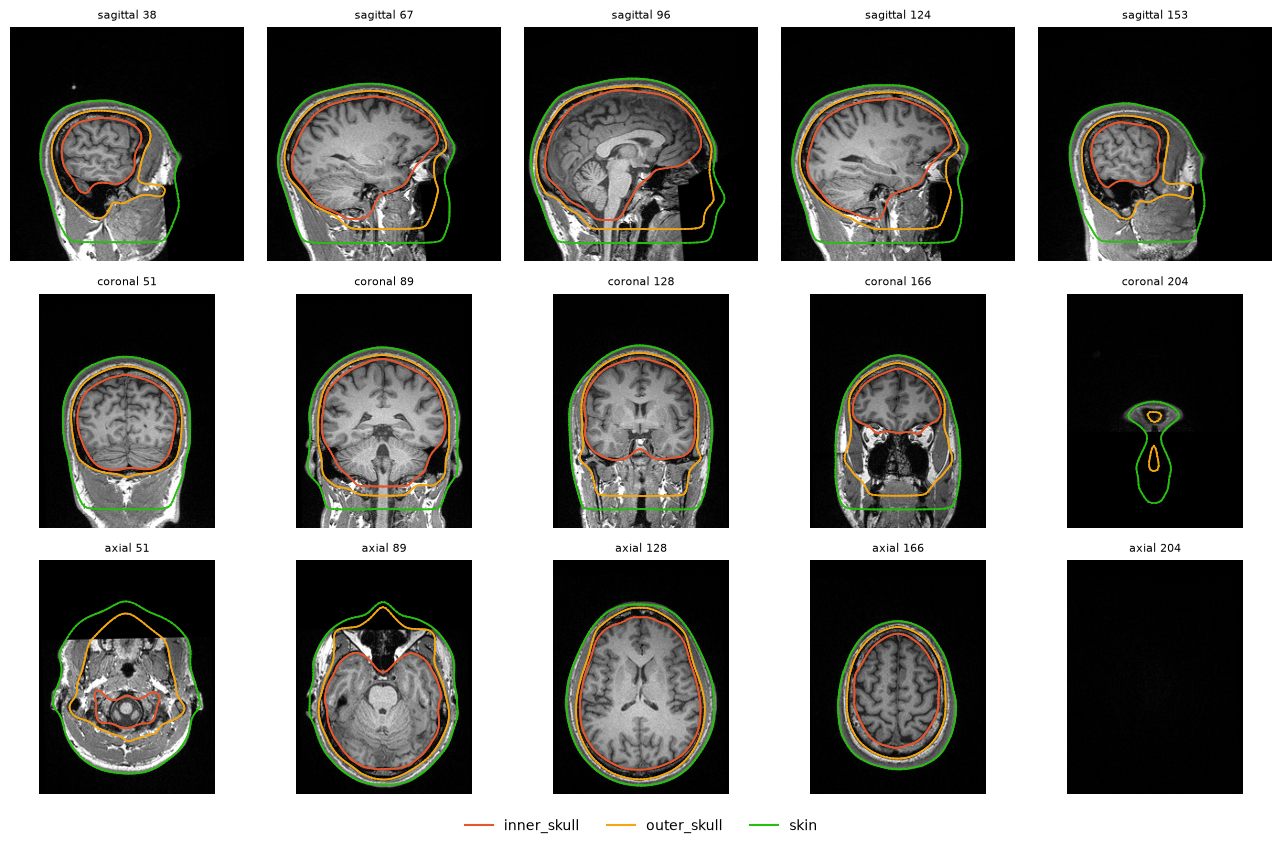

In [8]:
fig = mb.viz.plot_bem(bem_dir, t1, backend="matplotlib", fs_t1=t1_mgz)
plt.show()

### Your viewer of choice

| `VIEWER` | what you get | needs |
|---|---|---|
| `"pyvista"` | interactive 3D surfaces + MRI slices | included (`pyvista[jupyter]` for in-notebook 3D) |
| `"matplotlib"` | outlines over slices (above) | `[viz]` |
| `"mne"` | `mne.viz.plot_bem` | `[mne]` |
| `"freeview"` | FreeSurfer's viewer, separate window | FreeSurfer |

`fs_t1` tells `plot_bem` which frame the surfaces are in.

In [9]:
VIEWER = "pyvista"     # "pyvista" | "matplotlib" | "mne" | "freeview"

view = mb.viz.plot_bem(bem_dir, t1, backend=VIEWER, fs_t1=t1_mgz)

Widget(value='<iframe src="http://localhost:35943/index.html?ui=P_0x7e93b6716510_0&reconnect=auto" class="pyvi…

Downloaded WASM:
 - from: https://gitlab.kitware.com/api/v4/projects/13/packages/generic/vtk-wasm64-emscripten/9.7.1/vtk-9.7.1-wasm64-emscripten.tar.gz
 - to: /home/nino/miniconda3/envs/bem-release/lib/python3.12/site-packages/trame_vtklocal/module/serve/wasm64/9.7.1
Downloaded WASM:
 - from: https://gitlab.kitware.com/api/v4/projects/13/packages/generic/vtk-wasm32-emscripten/9.7.1/vtk-9.7.1-wasm32-emscripten.tar.gz
 - to: /home/nino/miniconda3/envs/bem-release/lib/python3.12/site-packages/trame_vtklocal/module/serve/wasm32/9.7.1


## 5. Use it in MNE

The subject folder follows MNE's layout, so the usual functions work: `mne.viz.plot_bem`, the coregistration GUI (`mne coreg`) to compute the head → MRI `trans` from your digitized electrodes, forward models...

MNE recommends 5120 triangles per layer for a 3-layer BEM, hence `ico=4` (MNE downsamples our ico-5 meshes exactly, since they share its vertex ordering).

In [10]:
import mne
mne.set_log_level("warning")

model = mne.make_bem_model(subject, ico=4, conductivity=(0.3, 0.006, 0.3), subjects_dir=SUBJECTS_DIR)
bem = mne.make_bem_solution(model)
bem

<ConductorModel | BEM (3 layers) solver=mne>

A volume source space can be built directly inside the inner skull:

In [11]:
src = mne.setup_volume_source_space(subject, pos=7.0, bem=bem, subjects_dir=SUBJECTS_DIR)
src

<SourceSpaces: [<volume, shape=(np.int64(21), np.int64(27), np.int64(22)), n_used=3584>] MRI (surface RAS) coords, subject 'sub-01', ~99.1 MiB>

## Your own data

Replace the download with your file. Any orientation and voxel size works; add a T2 if you have one (CHARM uses it to separate skull and CSF better):

```python
mb.bem_from_t1("my_subject", "my_T1w.nii.gz", out_dir, t2="my_T2w.nii.gz", subjects_dir=subjects_dir)
```

or from the terminal:

```bash
mindmap-bem run my_subject my_T1w.nii.gz --out out_dir --subjects-dir subjects_dir
```

If `subjects_dir` is your FreeSurfer `SUBJECTS_DIR` and the subject was reconstructed from the same scan, the BEM is written in that reconstruction's coordinates, ready to combine with a cortical source space.